# HMK / 03 — Are the daily, 1 hour and 15 minute state probabilities independent? (descriptive)

Protocol: [`HMK 006`](../../discussions/MNQ_Hierarchical_Markov/006_claude_hmk03_tier_independence.md). Code: `src/equity_trading/hmk.py`.

- **States** as in 02: daily 20 days ±5%; 1 h W = 40 / 60; 15 m W = 60 / 80; each intraday tier by (a) the set √time band or (b) the 3-state HMM on the window return (fitted once on the window, then a fixed classifier). 2 methods × 2 × 2 windows = 8 cases.
- **Parent of a bar** = the parent's last completed bar (15 m in day d → daily state of d−1; 15 m in hour h → 1 h state of h−1; 1 h in day d → daily state of d−1).
- **Links:** 15m | 1d, 1h | 1d, 15m | 1h.
- **Two questions per link:**
  1. Is the child's state independent of the parent's? P(child | parent) = P(child) — mutual information I(child; parent).
  2. Is the child's *transition* independent of the parent? P(child_{t+1} | child_t, parent) = P(child_{t+1} | child_t) — conditional mutual information I(child_{t+1}; parent | child_t). This is the (P of 15 m state at t+1 | current 1D state) question.
- **Two references:** (i) *circular shift* of the parent's states by ≥ 60 whole days (keeps each tier's own persistence): tests independence as such. (ii) *shuffled returns*: 15 m returns permuted within each time-of-day slot, all tiers rebuilt from them, same classifiers: the dependence that shared returns (the parent's window contains the child's bars) produce on their own.
- **Window:** 2020-01 – 2023-06 (halves reported without references).

Environment: `HMK_SYNTHETIC=1` (random-walk smoke run), `HMK_SYNTH_DIR`.

In [1]:
import json, os, sys, tempfile, warnings, itertools, time
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)
SYNTHETIC = os.environ.get("HMK_SYNTHETIC") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("HMK_SYNTH_DIR") or tempfile.mkdtemp(prefix="hmk_")
    os.environ["HMK_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]

REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "src"))
from equity_trading import hmk as H
from equity_trading import micro_bars as MB

D = dt.date
CFG = H.HMKConfig()
if SYNTHETIC:
    WINDOWS = {"all": (D(2020, 1, 1), D(2021, 6, 30)), "H1": (D(2020, 1, 1), D(2020, 9, 30)), "H2": (D(2020, 10, 1), D(2021, 6, 30))}
    if not (Path(os.environ["EQUITY_TRADING_DIR"]) / "Databento").exists():
        H.write_synthetic(os.environ["EQUITY_TRADING_DIR"], CFG.load_start, WINDOWS["all"][1], effect=0.0)
    N_SHIFT, N_SHUFFLE = 50, 20
else:
    WINDOWS = {"all": (D(2020, 1, 1), D(2023, 6, 30)), "H1": (D(2020, 1, 1), D(2021, 9, 30)), "H2": (D(2021, 10, 1), D(2023, 6, 30))}
    N_SHIFT, N_SHUFFLE = 500, 200
OUT = Path("03"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)
LINKS = ("15m|1d", "1h|1d", "15m|1h")
print("engine", H.HMK_VERSION, "| synthetic random walk" if SYNTHETIC else "| real data", "| references", N_SHIFT, N_SHUFFLE)

engine 0.1.0 | real data | references 500 200


In [2]:
m1 = MB.load_1m(CFG.root, CFG.load_start, WINDOWS["all"][1] + dt.timedelta(days=1))
BARS = H.session_bars(m1, CFG)
del m1
end = WINDOWS["all"][1]
BARS = {k: H.in_window(v, D(1900, 1, 1), end).reset_index(drop=True) for k, v in BARS.items()}
T = H.tiers_from_15m(BARS)
R15 = T["q"].ret_bp.to_numpy(float)
SLOT = T["q"].slot.to_numpy()
QD = pd.to_datetime(T["q"].trade_date).dt.date.to_numpy()
def masks_for(a, b):
    return {"15m": (QD >= a) & (QD <= b), "1h": np.array([(d >= a) & (d <= b) for d in T["hour_dates"]]),
            "1d": np.array([(d >= a) & (d <= b) for d in T["day_dates"]])}
M_ALL = masks_for(*WINDOWS["all"])
R = H.tier_returns_from(R15, T)
# HMMs on the window return, fitted once on the full window, then used as fixed classifiers
HMM = {}
for tier, w in (("1h", 40), ("1h", 60), ("15m", 60), ("15m", 80)):
    _, _, HMM[(tier, w)] = H.hmm_states(R[tier], w, M_ALL[tier], CFG)
    print(tier, w, "HMM means %", (HMM[(tier, w)].mu / 100).round(3))
CASES = {}
for method, w1, w15 in itertools.product(("band", "hmm"), (40, 60), (60, 80)):
    def spec(tier, w):
        return (H.TierSpec(tier, w, "band", H.band_for_window(tier, w)) if method == "band"
                else H.TierSpec(tier, w, "hmm", model=HMM[(tier, w)]))
    CASES[f"{method}_1hW{w1}_15mW{w15}"] = {"1d": H.TierSpec("1d", 20, "band", 0.05), "1h": spec("1h", w1), "15m": spec("15m", w15)}
print(list(CASES))

1h 40 HMM means % [-2.362  0.209  2.423]
1h 60 HMM means % [-2.265  0.691  3.205]
15m 60 HMM means % [-0.65  -0.112  0.902]
15m 80 HMM means % [-0.736 -0.189  1.016]
['band_1hW40_15mW60', 'band_1hW40_15mW80', 'band_1hW60_15mW60', 'band_1hW60_15mW80', 'hmm_1hW40_15mW60', 'hmm_1hW40_15mW80', 'hmm_1hW60_15mW60', 'hmm_1hW60_15mW80']


## 1. Statistics and references

In [3]:
rng = np.random.default_rng(0)
STATS, REAL = [], {}
T0 = time.time()
SHUF_R = [H.shuffle_within_slot(R15, SLOT, rng) for _ in range(N_SHUFFLE)]
for name, specs in CASES.items():
    real = H.dependence(R15, T, specs, M_ALL); REAL[name] = real
    shift = H.circular_shift_null(R15, T, specs, M_ALL, N_SHIFT, rng)
    shuf = [H.dependence(r, T, specs, M_ALL) for r in SHUF_R]
    for link in LINKS:
        row = {"case": name, "link": link, "n": real[link]["n"]}
        for stat in ("mi", "cmi"):
            x = real[link][stat]
            s1 = np.array(shift[link][stat]); s2 = np.array([s[link][stat] for s in shuf])
            row.update({stat: x, f"{stat}_shift_mean": s1.mean(), f"{stat}_shift_q95": np.quantile(s1, .95),
                        f"{stat}_p_shift": (1 + (s1 >= x).sum()) / (1 + len(s1)),
                        f"{stat}_shuffle_mean": s2.mean(), f"{stat}_shuffle_q95": np.quantile(s2, .95),
                        f"{stat}_p_shuffle": (1 + (s2 >= x).sum()) / (1 + len(s2)), f"{stat}_excess_vs_shuffle": x - s2.mean()})
        STATS.append(row)
    print(name, f"{time.time() - T0:.0f}s", flush=True)
STATS = pd.DataFrame(STATS); STATS.to_csv(OUT / "03_stats.csv", index=False)
show = ["case", "link", "n", "mi", "mi_shift_q95", "mi_p_shift", "mi_shuffle_mean", "mi_p_shuffle",
        "cmi", "cmi_shift_q95", "cmi_p_shift", "cmi_shuffle_mean", "cmi_p_shuffle"]
display(STATS[show].round(5))

band_1hW40_15mW60 23s
band_1hW40_15mW80 45s
band_1hW60_15mW60 66s
band_1hW60_15mW80 88s
hmm_1hW40_15mW60 112s
hmm_1hW40_15mW80 135s
hmm_1hW60_15mW60 159s
hmm_1hW60_15mW80 183s


,case,link,n,mi,mi_shift_q95,mi_p_shift,mi_shuffle_mean,mi_p_shuffle,cmi,cmi_shift_q95,cmi_p_shift,cmi_shuffle_mean,cmi_p_shuffle
0,band_1hW40_15mW60,15m|1d,81052,0.02011,0.00522,0.002,0.00264,0.00498,0.00247,0.00072,0.002,0.00018,0.00498
1,band_1hW40_15mW60,1h|1d,20263,0.02948,0.00758,0.002,0.01746,0.01990,0.00296,0.00128,0.002,0.00089,0.00498
2,band_1hW40_15mW60,15m|1h,81140,0.11346,0.00280,0.002,0.12639,0.97512,0.00490,0.00043,0.002,0.00399,0.00995
3,band_1hW40_15mW80,15m|1d,81052,0.02573,0.00588,0.002,0.00497,0.00498,0.00233,0.00060,0.002,0.00023,0.00498
4,band_1hW40_15mW80,1h|1d,20263,0.02948,0.00713,0.002,0.01746,0.01990,0.00296,0.00126,0.002,0.00089,0.00498
5,band_1hW40_15mW80,15m|1h,81140,0.16854,0.00326,0.002,0.18740,0.98507,0.00503,0.00042,0.002,0.00535,0.74627
6,band_1hW60_15mW60,15m|1d,81052,0.02011,0.00511,0.002,0.00264,0.00498,0.00247,0.00062,0.002,0.00018,0.00498
7,band_1hW60_15mW60,1h|1d,20263,0.04957,0.00961,0.002,0.03204,0.02488,0.00346,0.00126,0.002,0.00131,0.00498
8,band_1hW60_15mW60,15m|1h,81140,0.07498,0.00288,0.002,0.07930,0.74627,0.00352,0.00046,0.002,0.00242,0.00498
9,band_1hW60_15mW80,15m|1d,81052,0.02573,0.00590,0.002,0.00497,0.00498,0.00233,0.00060,0.002,0.00023,0.00498


## 2. P(child state | parent state)

Rows: the parent's last completed state. A row equal to the child's overall shares means independence.

In [4]:
TAB = []
for name, real in REAL.items():
    for link in LINKS:
        C = real[link]["counts"]
        P = H.cond_tables(C); P.loc["overall"] = C.sum(1) / C.sum()
        TAB.append(P.reset_index(names="row").assign(case=name, link=link))
TAB = pd.concat(TAB); TAB.to_csv(OUT / "03_conditional_states.csv", index=False)
for name in CASES:
    print("===", name)
    display(TAB[TAB.case == name].set_index(["link", "row"])[list(H.STATE_NAMES)].round(3))

=== band_1hW40_15mW60


bear   side   bull
link   row                             
15m|1d parent bear  0.306  0.402  0.292
       parent side  0.174  0.636  0.190
       parent bull  0.132  0.672  0.196
       overall      0.184  0.607  0.210
1h|1d  parent bear  0.365  0.400  0.235
       parent side  0.187  0.607  0.206
       parent bull  0.094  0.623  0.283
       overall      0.188  0.576  0.236
15m|1h parent bear  0.514  0.414  0.071
       parent side  0.134  0.709  0.157
       parent bull  0.041  0.511  0.448
       overall      0.183  0.607  0.210

=== band_1hW40_15mW80


bear   side   bull
link   row                             
15m|1d parent bear  0.343  0.369  0.289
       parent side  0.176  0.624  0.201
       parent bull  0.124  0.665  0.211
       overall      0.188  0.592  0.220
1h|1d  parent bear  0.365  0.400  0.235
       parent side  0.187  0.607  0.206
       parent bull  0.094  0.623  0.283
       overall      0.188  0.576  0.236
15m|1h parent bear  0.591  0.366  0.043
       parent side  0.122  0.725  0.153
       parent bull  0.027  0.449  0.524
       overall      0.188  0.592  0.220

=== band_1hW60_15mW60


bear   side   bull
link   row                             
15m|1d parent bear  0.306  0.402  0.292
       parent side  0.174  0.636  0.190
       parent bull  0.132  0.672  0.196
       overall      0.184  0.607  0.210
1h|1d  parent bear  0.408  0.404  0.188
       parent side  0.180  0.633  0.187
       parent bull  0.068  0.598  0.334
       overall      0.183  0.582  0.235
15m|1h parent bear  0.469  0.432  0.100
       parent side  0.144  0.682  0.174
       parent bull  0.059  0.557  0.385
       overall      0.183  0.607  0.210

... (6 outputs left out)

=== hmm_1hW60_15mW60


bear   side   bull
link   row                             
15m|1d parent bear  0.506  0.244  0.250
       parent side  0.255  0.429  0.316
       parent bull  0.212  0.446  0.342
       overall      0.285  0.402  0.313
1h|1d  parent bear  0.631  0.179  0.190
       parent side  0.392  0.418  0.190
       parent bull  0.193  0.458  0.348
       overall      0.369  0.389  0.241
15m|1h parent bear  0.430  0.353  0.217
       parent side  0.174  0.479  0.347
       parent bull  0.239  0.352  0.409
       overall      0.285  0.402  0.314

=== hmm_1hW60_15mW80


bear   side   bull
link   row                             
15m|1d parent bear  0.522  0.210  0.268
       parent side  0.247  0.416  0.337
       parent bull  0.203  0.410  0.387
       overall      0.280  0.378  0.341
1h|1d  parent bear  0.631  0.179  0.190
       parent side  0.392  0.418  0.190
       parent bull  0.193  0.458  0.348
       overall      0.369  0.389  0.241
15m|1h parent bear  0.445  0.352  0.203
       parent side  0.153  0.451  0.397
       parent bull  0.234  0.300  0.466
       overall      0.280  0.378  0.342

## 3. P(child_{t+1} | child_t, parent) — the child's transition matrix under each parent state

If the three parent rows match 'pooled', the parent does not change the child's transitions.

In [5]:
TR = []
for name, real in REAL.items():
    for link in LINKS:
        for g, M in H.cond_transitions(real[link]["counts3"]).items():
            TR.append(M.reset_index(names="from").assign(case=name, link=link, parent=g,
                      n=int(real[link]["counts3"].sum() if g == "pooled" else real[link]["counts3"][list(H.STATE_NAMES).index(g.split()[-1])].sum())))
TR = pd.concat(TR); TR.to_csv(OUT / "03_conditional_transitions.csv", index=False)
for name in CASES:
    print("===", name)
    display(TR[(TR.case == name)].pivot_table(index=["link", "parent", "from"], values=list(H.STATE_NAMES), sort=False)[list(H.STATE_NAMES)].round(3))

=== band_1hW40_15mW60


bear   side   bull
link   parent      from                     
15m|1d parent bear bear  0.923  0.076  0.001
                   side  0.056  0.886  0.058
                   bull  0.001  0.077  0.923
       parent side bear  0.912  0.087  0.000
                   side  0.024  0.949  0.028
                   bull  0.000  0.092  0.908
       parent bull bear  0.917  0.083  0.000
                   side  0.017  0.959  0.024
                   bull  0.000  0.085  0.915
       pooled      bear  0.917  0.083  0.000
                   side  0.025  0.945  0.030
                   bull  0.000  0.086  0.914
1h|1d  parent bear bear  0.912  0.087  0.001
                   side  0.071  0.857  0.073
                   bull  0.004  0.107  0.889
       parent side bear  0.895  0.105  0.001
                   side  0.032  0.930  0.037
                   bull  0.000  0.105  0.895
       parent bull bear  0.877  0.123  0.000
                   side  0.021  0.940  0.039
                   bull  0.000  0.099  0.901
       pooled      bear  0.898  0.102  0.001
                   side  0.033  0.925  0.042
                   bull  0.001  0.103  0.896
15m|1h parent bear bear  0.934  0.066  0.000
                   side  0.070  0.897  0.033
                   bull  0.001  0.164  0.835
       parent side bear  0.901  0.099  0.000
                   side  0.020  0.957  0.024
                   bull  0.000  0.100  0.900
       parent bull bear  0.863  0.134  0.003
                   side  0.016  0.936  0.048
                   bull  0.000  0.065  0.934
       pooled      bear  0.917  0.083  0.000
                   side  0.025  0.945  0.030
                   bull  0.000  0.086  0.914

=== band_1hW40_15mW80


bear   side   bull
link   parent      from                     
15m|1d parent bear bear  0.942  0.058  0.000
                   side  0.052  0.891  0.057
                   bull  0.000  0.070  0.930
       parent side bear  0.927  0.073  0.000
                   side  0.021  0.956  0.024
                   bull  0.000  0.074  0.926
       parent bull bear  0.917  0.083  0.000
                   side  0.016  0.959  0.024
                   bull  0.000  0.079  0.921
       pooled      bear  0.929  0.071  0.000
                   side  0.022  0.950  0.028
                   bull  0.000  0.074  0.926
1h|1d  parent bear bear  0.912  0.087  0.001
                   side  0.071  0.857  0.073
                   bull  0.004  0.107  0.889
       parent side bear  0.895  0.105  0.001
                   side  0.032  0.930  0.037
                   bull  0.000  0.105  0.895
       parent bull bear  0.877  0.123  0.000
                   side  0.021  0.940  0.039
                   bull  0.000  0.099  0.901
       pooled      bear  0.898  0.102  0.001
                   side  0.033  0.925  0.042
                   bull  0.001  0.103  0.896
15m|1h parent bear bear  0.953  0.047  0.000
                   side  0.060  0.918  0.022
                   bull  0.000  0.140  0.860
       parent side bear  0.898  0.102  0.000
                   side  0.019  0.958  0.023
                   bull  0.000  0.098  0.902
       parent bull bear  0.862  0.138  0.000
                   side  0.013  0.937  0.051
                   bull  0.000  0.054  0.946
       pooled      bear  0.929  0.071  0.000
                   side  0.022  0.950  0.028
                   bull  0.000  0.075  0.925

=== band_1hW60_15mW60


bear   side   bull
link   parent      from                     
15m|1d parent bear bear  0.923  0.076  0.001
                   side  0.056  0.886  0.058
                   bull  0.001  0.077  0.923
       parent side bear  0.912  0.087  0.000
                   side  0.024  0.949  0.028
                   bull  0.000  0.092  0.908
       parent bull bear  0.917  0.083  0.000
                   side  0.017  0.959  0.024
                   bull  0.000  0.085  0.915
       pooled      bear  0.917  0.083  0.000
                   side  0.025  0.945  0.030
                   bull  0.000  0.086  0.914
1h|1d  parent bear bear  0.919  0.081  0.001
                   side  0.077  0.873  0.050
                   bull  0.000  0.102  0.898
       parent side bear  0.904  0.096  0.000
                   side  0.027  0.940  0.033
                   bull  0.000  0.109  0.891
       parent bull bear  0.862  0.138  0.000
                   side  0.018  0.941  0.042
                   bull  0.000  0.080  0.920
       pooled      bear  0.905  0.095  0.000
                   side  0.030  0.932  0.038
                   bull  0.000  0.094  0.906
15m|1h parent bear bear  0.934  0.066  0.000
                   side  0.061  0.899  0.040
                   bull  0.001  0.140  0.859
       parent side bear  0.909  0.091  0.000
                   side  0.020  0.955  0.025
                   bull  0.000  0.095  0.905
       parent bull bear  0.854  0.143  0.003
                   side  0.019  0.942  0.039
                   bull  0.000  0.066  0.934
       pooled      bear  0.917  0.083  0.000
                   side  0.025  0.945  0.030
                   bull  0.000  0.086  0.914

... (6 outputs left out)

=== hmm_1hW60_15mW60


bear   side   bull
link   parent      from                     
15m|1d parent bear bear  0.969  0.020  0.011
                   side  0.038  0.910  0.053
                   bull  0.024  0.049  0.927
       parent side bear  0.967  0.025  0.008
                   side  0.015  0.962  0.024
                   bull  0.006  0.031  0.962
       parent bull bear  0.971  0.020  0.009
                   side  0.011  0.966  0.022
                   bull  0.005  0.032  0.963
       pooled      bear  0.969  0.022  0.010
                   side  0.016  0.958  0.026
                   bull  0.008  0.034  0.958
1h|1d  parent bear bear  0.979  0.020  0.000
                   side  0.056  0.895  0.049
                   bull  0.000  0.039  0.961
       parent side bear  0.974  0.026  0.000
                   side  0.022  0.961  0.017
                   bull  0.000  0.037  0.963
       parent bull bear  0.973  0.027  0.000
                   side  0.018  0.962  0.020
                   bull  0.000  0.030  0.970
       pooled      bear  0.975  0.024  0.000
                   side  0.023  0.956  0.021
                   bull  0.000  0.034  0.966
15m|1h parent bear bear  0.971  0.024  0.005
                   side  0.023  0.944  0.033
                   bull  0.012  0.043  0.945
       parent side bear  0.967  0.023  0.010
                   side  0.011  0.969  0.020
                   bull  0.006  0.030  0.964
       parent bull bear  0.964  0.016  0.020
                   side  0.016  0.955  0.029
                   bull  0.008  0.033  0.959
       pooled      bear  0.969  0.022  0.010
                   side  0.016  0.958  0.026
                   bull  0.008  0.034  0.958

=== hmm_1hW60_15mW80


bear   side   bull
link   parent      from                     
15m|1d parent bear bear  0.974  0.016  0.009
                   side  0.037  0.921  0.043
                   bull  0.020  0.029  0.950
       parent side bear  0.973  0.019  0.007
                   side  0.011  0.970  0.019
                   bull  0.005  0.023  0.972
       parent bull bear  0.976  0.016  0.008
                   side  0.010  0.971  0.019
                   bull  0.003  0.023  0.974
       pooled      bear  0.974  0.017  0.008
                   side  0.013  0.966  0.021
                   bull  0.007  0.024  0.970
1h|1d  parent bear bear  0.979  0.020  0.000
                   side  0.056  0.895  0.049
                   bull  0.000  0.039  0.961
       parent side bear  0.974  0.026  0.000
                   side  0.022  0.961  0.017
                   bull  0.000  0.037  0.963
       parent bull bear  0.973  0.027  0.000
                   side  0.018  0.962  0.020
                   bull  0.000  0.030  0.970
       pooled      bear  0.975  0.024  0.000
                   side  0.023  0.956  0.021
                   bull  0.000  0.034  0.966
15m|1h parent bear bear  0.976  0.020  0.004
                   side  0.020  0.955  0.025
                   bull  0.010  0.030  0.960
       parent side bear  0.972  0.018  0.010
                   side  0.009  0.974  0.017
                   bull  0.005  0.022  0.974
       parent bull bear  0.972  0.009  0.018
                   side  0.011  0.965  0.024
                   bull  0.007  0.022  0.971
       pooled      bear  0.974  0.017  0.008
                   side  0.013  0.966  0.021
                   bull  0.007  0.023  0.970

## 4. Halves (no references)

In [6]:
HALF = []
for win in ("H1", "H2"):
    mk = masks_for(*WINDOWS[win])
    for name, specs in CASES.items():
        d = H.dependence(R15, T, specs, mk)
        for link in LINKS:
            HALF.append({"window": win, "case": name, "link": link, "mi": d[link]["mi"], "cmi": d[link]["cmi"], "n": d[link]["n"]})
HALF = pd.DataFrame(HALF)
both = pd.concat([HALF, STATS[["case", "link", "mi", "cmi", "n"]].assign(window="all")])
both.to_csv(OUT / "03_halves.csv", index=False)
display(both.pivot_table(index=["case", "link"], columns="window", values=["mi", "cmi"], sort=False).round(5))

mi                        cmi                  
window                         H1       H2      all       H1       H2      all
case              link                                                        
band_1hW40_15mW60 15m|1d  0.02253  0.01667  0.02011  0.00287  0.00228  0.00247
                  1h|1d   0.03643  0.02314  0.02948  0.00506  0.00217  0.00296
                  15m|1h  0.11010  0.12300  0.11346  0.00584  0.00475  0.00490
band_1hW40_15mW80 15m|1d  0.02563  0.02150  0.02573  0.00226  0.00215  0.00233
                  1h|1d   0.03643  0.02314  0.02948  0.00506  0.00217  0.00296
                  15m|1h  0.15640  0.18244  0.16854  0.00523  0.00523  0.00503
band_1hW60_15mW60 15m|1d  0.02253  0.01667  0.02011  0.00287  0.00228  0.00247
                  1h|1d   0.05325  0.04631  0.04957  0.00390  0.00352  0.00346
                  15m|1h  0.07502  0.07860  0.07498  0.00484  0.00295  0.00352
band_1hW60_15mW80 15m|1d  0.02563  0.02150  0.02573  0.00226  0.00215  0.00233
                  1h|1d   0.05325  0.04631  0.04957  0.00390  0.00352  0.00346
                  15m|1h  0.09848  0.11030  0.10219  0.00353  0.00294  0.00300
hmm_1hW40_15mW60  15m|1d  0.02980  0.02013  0.02545  0.00174  0.00195  0.00195
                  1h|1d   0.04628  0.02510  0.03659  0.00307  0.00174  0.00220
                  15m|1h  0.08158  0.05318  0.06517  0.00215  0.00194  0.00189
hmm_1hW40_15mW80  15m|1d  0.03323  0.02532  0.03107  0.00155  0.00173  0.00168
                  1h|1d   0.04628  0.02510  0.03659  0.00307  0.00174  0.00220
                  15m|1h  0.11707  0.09599  0.10739  0.00222  0.00220  0.00210
hmm_1hW60_15mW60  15m|1d  0.02980  0.02013  0.02545  0.00174  0.00195  0.00195
                  1h|1d   0.05960  0.04699  0.05596  0.00182  0.00108  0.00130
                  15m|1h  0.05371  0.02680  0.03712  0.00180  0.00128  0.00139
hmm_1hW60_15mW80  15m|1d  0.03323  0.02532  0.03107  0.00155  0.00173  0.00168
                  1h|1d   0.05960  0.04699  0.05596  0.00182  0.00108  0.00130
                  15m|1h  0.06362  0.04334  0.05341  0.00126  0.00129  0.00131

## 5. Heatmaps: 15 m transitions under each daily state (all cases)

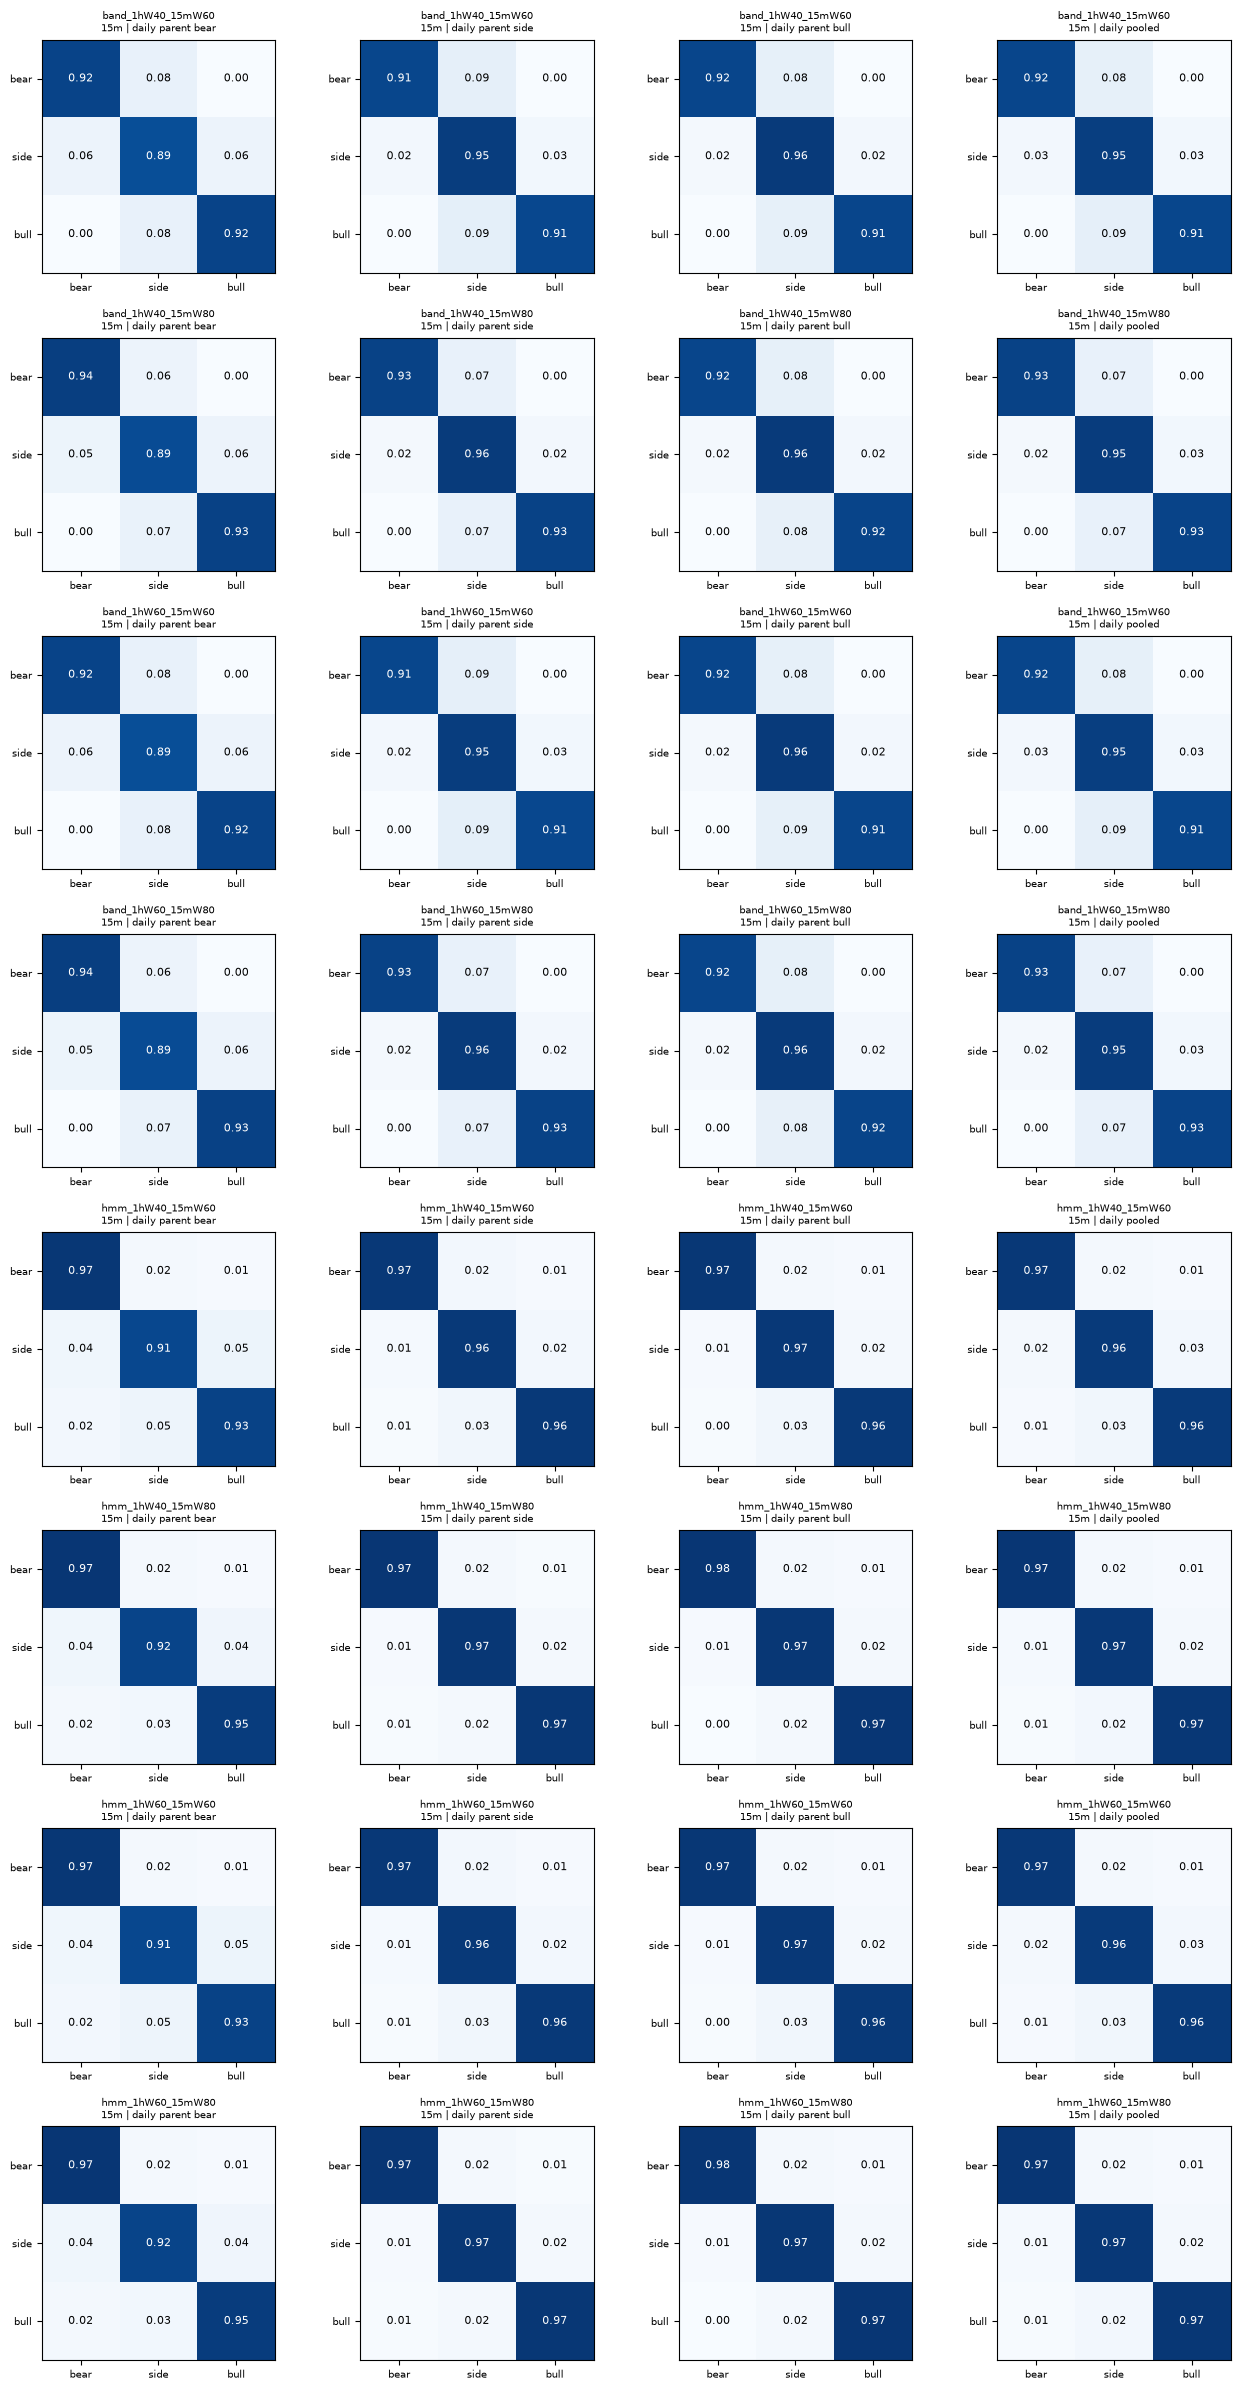

In [7]:
fig, ax = plt.subplots(len(CASES), 4, figsize=(13, 3.0 * len(CASES)))
for i, (name, real) in enumerate(REAL.items()):
    for j, (g, M) in enumerate(H.cond_transitions(real["15m|1d"]["counts3"]).items()):
        a = ax[i, j]; v = M.to_numpy(float); a.imshow(v, vmin=0, vmax=1, cmap="Blues")
        for (p, q), x in np.ndenumerate(v):
            a.text(q, p, f"{x:.2f}" if np.isfinite(x) else "-", ha="center", va="center", color="k" if not np.isfinite(x) or x < 0.6 else "w", fontsize=8)
        a.set_xticks(range(3), H.STATE_NAMES, fontsize=7); a.set_yticks(range(3), H.STATE_NAMES, fontsize=7)
        a.set_title(f"{name}\n15m | daily {g}", fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "03_transitions_15m_by_daily.png", dpi=100); plt.show()
json.dump({"version": H.HMK_VERSION, "synthetic": SYNTHETIC, "windows": {k: [str(a), str(b)] for k, (a, b) in WINDOWS.items()},
           "n_shift": N_SHIFT, "n_shuffle": N_SHUFFLE, "cases": list(CASES),
           "hmm_means_pct": {f"{t}_W{w}": (m.mu / 100).round(4).tolist() for (t, w), m in HMM.items()}},
          open(OUT / "03_run.json", "w"), indent=1)